# 05 · Cold Start

Everything so far assumed a user with history. But the first time someone arrives,
they have rated *nothing* — and collaborative filtering has nothing to find
neighbours from, matrix factorization has no learned vector for them, and even
content-based has no taste profile yet. **Popularity, which ignores the user, keeps
working.** That is the cold-start problem, and it is why every real system falls
back to "most popular" for new users.

We simulate a new user, reveal their ratings one at a time, and watch
collaborative filtering wake up and overtake popularity after a single rating —
the **explore–exploit** trade-off from the bandits world: you must recommend
*something* to learn a taste, trading immediate relevance for information.

In [1]:
# --- make the notebook runnable from anywhere: find the repo root, add to path, chdir ---
import os
import sys
from pathlib import Path

_root = Path.cwd()
while not (_root / "pyproject.toml").exists() and _root != _root.parent:
    _root = _root.parent
sys.path.insert(0, str(_root))
os.chdir(_root)

%matplotlib inline
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 120)

from src.artifacts import save_figure, save_json
from src.config import get_settings

SETTINGS = get_settings()
print("project root:", _root)
print("seed:", SETTINGS.seed, "| top_k:", SETTINGS.top_k)

project root: /workspaces/recommender_101
seed: 42 | top_k: 10


In [2]:
from sklearn.preprocessing import normalize

from src.data.ratings import item_popularity, load_movielens
from src.evaluation.ranking import recall_at_k
from src.evaluation.splits import leave_last_out

data = load_movielens()
matrix = data.matrix.tocsr()
ts = data.timestamps.tocsr()
n_users, n_items = matrix.shape
k = SETTINGS.top_k
LIKE = SETTINGS.like_threshold

split = leave_last_out(
    matrix, n_holdout=SETTINGS.split.n_holdout, min_train=SETTINGS.split.min_train,
    timestamps=data.timestamps, seed=SETTINGS.seed,
)
population = split.train.tocsr()                       # the existing users CF learns from
normed_pop = normalize(population)                     # L2-normalized rows for cosine
features_norm = normalize(data.item_features.astype(float))  # (items x genres)
pop_counts = item_popularity(population)
pop_rank = np.argsort(pop_counts)[::-1]
print("population:", population.shape)

population: (610, 9724)


## One new user, revealed one rating at a time

For a sample of users we take their liked movies (rating ≥ 4), reveal the first
`n` of them (by time) as the only history the system has, and ask each method to
recommend the *rest*. All three recommenders are computed **from scratch** for the
new user against the existing population — no retraining required.

In [3]:
def recommend_cold(new_vec, revealed, method):
    exclude = set(int(i) for i in revealed)
    if method == "popularity":
        return [i for i in pop_rank if i not in exclude][:k]
    norm = np.linalg.norm(new_vec)
    if norm == 0:                      # a brand-new user: no signal at all
        return []
    if method == "user_knn":
        sims = normed_pop @ (new_vec / norm)          # cosine to every existing user
        nbr = np.argpartition(-sims, SETTINGS.knn.n_neighbors)[:SETTINGS.knn.n_neighbors]
        scores = np.asarray(sims[nbr] @ population[nbr]).ravel()
    else:                              # content
        prof = np.asarray(features_norm[list(revealed)].sum(axis=0)).ravel()
        prof = prof / (np.linalg.norm(prof) or 1.0)
        scores = features_norm @ prof
    scores = np.asarray(scores, dtype=float)
    scores[list(exclude)] = -np.inf
    return np.argsort(scores)[::-1][:k].tolist()


rng = np.random.default_rng(SETTINGS.seed)
candidates = []
for u in range(n_users):
    s, e = matrix.indptr[u], matrix.indptr[u + 1]
    items, vals, times = matrix.indices[s:e], matrix.data[s:e], ts.data[s:e]
    liked = items[vals >= LIKE]
    if len(liked) >= 25:
        candidates.append((u, liked[np.argsort(times[vals >= LIKE])]))  # liked, time-ordered
sample = [candidates[i] for i in rng.choice(len(candidates), size=60, replace=False)]

n_values = [0, 1, 2, 3, 5, 10, 20]
methods = ["popularity", "user_knn", "content"]
curve = {m: [] for m in methods}
for n in n_values:
    per_method = {m: [] for m in methods}
    for u, liked in sample:
        revealed, targets = liked[:n], liked[n:]
        if len(targets) == 0:
            continue
        new_vec = np.zeros(n_items)
        new_vec[revealed] = matrix[u, revealed].toarray().ravel() if n else 0.0
        for m in methods:
            recs = recommend_cold(new_vec, revealed, m)
            per_method[m].append(recall_at_k(np.array(recs, dtype=int), targets, k) if recs else 0.0)
    for m in methods:
        curve[m].append(float(np.mean(per_method[m])))

save_json({"n_revealed": n_values, **curve}, "05_cold_start_curve")
pd.DataFrame(curve, index=n_values).rename_axis("ratings revealed").round(4)

,popularity,user_knn,content
ratings revealed,,,
0,0.0641,0.0000,0.0000
1,0.0614,0.0674,0.0028
2,0.0609,0.0720,0.0024
3,0.0602,0.0702,0.0022
5,0.0598,0.0670,0.0015
10,0.0551,0.0662,0.0017
20,0.0443,0.0766,0.0028


## The cold-start cliff, and the crossover

At **zero** ratings the personalized methods return *nothing useful* — only
popularity produces sensible recommendations. After a **single** revealed rating,
collaborative filtering already overtakes popularity and keeps climbing.
Content-based, by contrast, stays weak here: MovieLens's 19 coarse genres carry
little ranking signal, and content's real strength is cold *items* (a brand-new
movie with features but no ratings), not cold *users*. The practical system is a
**hybrid**: serve popularity to cold users, switch to collaborative filtering /
matrix factorization as history accumulates, and lean on content for cold items.

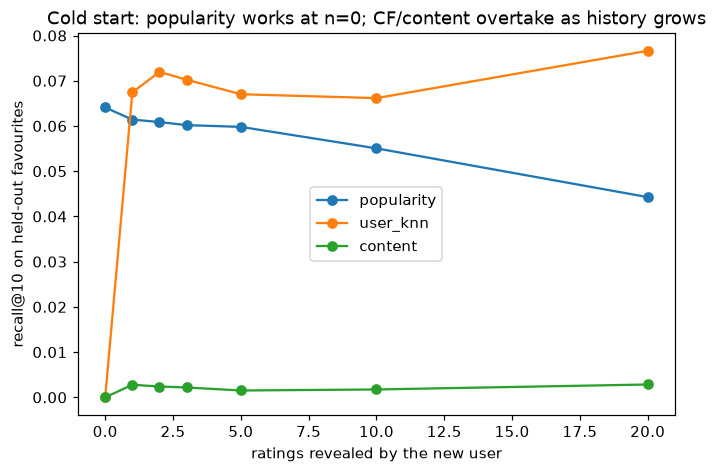

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for m in methods:
    ax.plot(n_values, curve[m], marker="o", label=m)
ax.set_xlabel("ratings revealed by the new user")
ax.set_ylabel(f"recall@{k} on held-out favourites")
ax.set_title("Cold start: popularity works at n=0; CF/content overtake as history grows")
ax.legend()
save_figure(fig, "05_cold_start_curve")
plt.show()

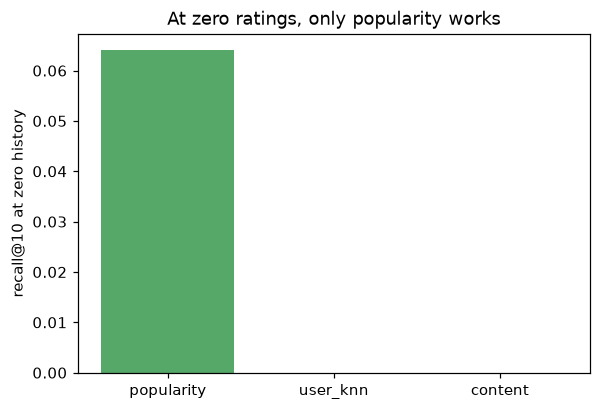

user_knn overtakes popularity after 1 revealed ratings


In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
n0 = {m: curve[m][0] for m in methods}
colors = ["#55A868" if m == "popularity" else "#C44E52" for m in methods]
ax.bar(list(n0), list(n0.values()), color=colors)
ax.set_ylabel(f"recall@{k} at zero history")
ax.set_title("At zero ratings, only popularity works")
save_figure(fig, "05_cold_start_n0")
plt.show()

crossover = next((n for n in n_values if curve["user_knn"][n_values.index(n)] > curve["popularity"][n_values.index(n)]), None)
save_json({
    "recall_at_zero_history": n0,
    "user_knn_overtakes_popularity_at_n": crossover,
    "note": "MF shares CF's failure: a brand-new user has no learned embedding, so it also needs a popularity/content fallback until history accrues.",
}, "05_coldstart_summary")
print("user_knn overtakes popularity after", crossover, "revealed ratings")

## Cold start *is* explore–exploit

A new user is a bandit problem: every recommendation is a chance to *exploit* what
little you know for immediate relevance, or *explore* to learn their taste faster.
Popularity is pure exploitation of the crowd's prior; good cold-start policies add
deliberate exploration — the direct link to `bandits_101`.

**Next:** [06 · Decision Framework](06_decision_framework.ipynb) — turn all of this
into a one-page guide for choosing a method.